# Notebook 01 — Data Exploration & Feature Selection

**Project:** Student Academic Performance Prediction using Deep Neural Networks  
**Prediction stage:** After first-period (`G1`) and second-period (`G2`) grades are available.

### What we will do
1. Load and understand the dataset.
2. Create the three-class target from final grade `G3`.
3. Perform exploratory data analysis (EDA).
4. Create reproducible train/validation/test splits.
5. Rank input features using **training data only**.
6. Select a compact feature set (including `G1` and `G2`).
7. Save the feature list for the next notebooks.

**Important:** `G3` determines the label, so it must never be an input. We will not train a DNN or inspect test-set performance in this notebook.


## 1. Imports and paths

**Why?** All notebooks should read the same dataset and use the same random seed. Run this notebook from the `notebooks/` folder in Jupyter or VS Code.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif

SEED = 42
DATA_PATH = Path("../data/student-por.csv")
CONFIG_PATH = Path("../models/selected_features.json")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Put student-por.csv inside the data/ folder."
    )

df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 2. Understand the data

**Why?** Before building a model, check the dataset size, data types, duplicates and missing values. Do not automatically delete rows without understanding the problem.

In [2]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nData types:")
display(df.dtypes.value_counts().rename("count").to_frame())

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary of numerical columns:")
display(df.describe().T)

Rows: 649
Columns: 33

Data types:


,count
object,17
int64,16



Missing values per column:


,missing_count
school,0
paid,0
G2,0
G1,0
absences,0
health,0
Walc,0
Dalc,0
goout,0
freetime,0



Duplicate rows: 0

Summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.568567,0.748660,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.930663,0.829510,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.221880,0.593235,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.930663,0.955717,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.184900,1.175766,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.502311,0.924834,1.0,1.0,1.0,2.0,5.0


## 3. Create the prediction target

We predict **final academic performance category**, not the exact grade.

- **Low:** `G3` from 0 to 9
- **Average:** `G3` from 10 to 13
- **Good:** `G3` from 14 to 20

`G1` and `G2` are valid inputs **only because our application predicts after the second grading period**.

Class distribution:


performance_category
Low        100
Average    355
Good       194
Name: count, dtype: int64

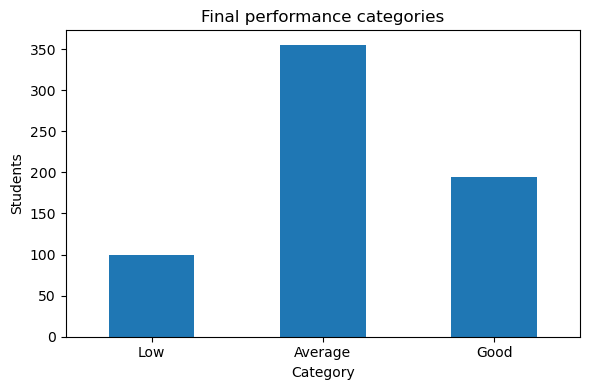

In [3]:
def performance_category(final_grade):
    if final_grade < 10:
        return "Low"
    if final_grade < 14:
        return "Average"
    return "Good"

df["performance_category"] = df["G3"].apply(performance_category)

print("Class distribution:")
display(df["performance_category"].value_counts().reindex(["Low", "Average", "Good"]))

fig, ax = plt.subplots(figsize=(6, 4))
df["performance_category"].value_counts().reindex(
    ["Low", "Average", "Good"]
).plot(kind="bar", ax=ax)
ax.set(title="Final performance categories", xlabel="Category", ylabel="Students")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis (EDA)

We examine the relationship of `G1`, `G2`, study time, absences and previous failures with final performance. These plots are **descriptive**, not proof of causation or proof that a feature should be selected.

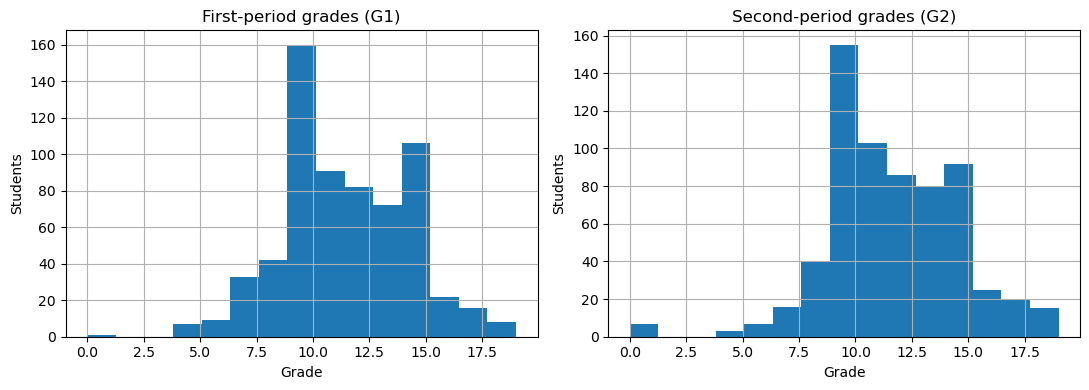


G1 — average by final performance category


,mean
performance_category,
Low,7.78
Average,10.86
Good,14.24



G2 — average by final performance category


,mean
performance_category,
Low,7.53
Average,10.97
Good,14.75



studytime — average by final performance category


,mean
performance_category,
Low,1.61
Average,1.89
Good,2.18



absences — average by final performance category


,mean
performance_category,
Low,4.61
Average,3.72
Good,3.05



failures — average by final performance category


,mean
performance_category,
Low,0.75
Average,0.19
Good,0.02


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["G1"].hist(bins=15, ax=axes[0])
axes[0].set(title="First-period grades (G1)", xlabel="Grade", ylabel="Students")
df["G2"].hist(bins=15, ax=axes[1])
axes[1].set(title="Second-period grades (G2)", xlabel="Grade", ylabel="Students")
plt.tight_layout()
plt.show()

for feature in ["G1", "G2", "studytime", "absences", "failures"]:
    print(f"\n{feature} — average by final performance category")
    display(
        df.groupby("performance_category")[feature]
          .mean().reindex(["Low", "Average", "Good"])
          .round(2).to_frame("mean")
    )

Numerical feature correlations with final grade (EDA only):


,Pearson correlation
G2,0.918548
G1,0.826387
studytime,0.249789
Medu,0.240151
Fedu,0.211800
famrel,0.063361
goout,-0.087641
absences,-0.091379
health,-0.098851
age,-0.106505


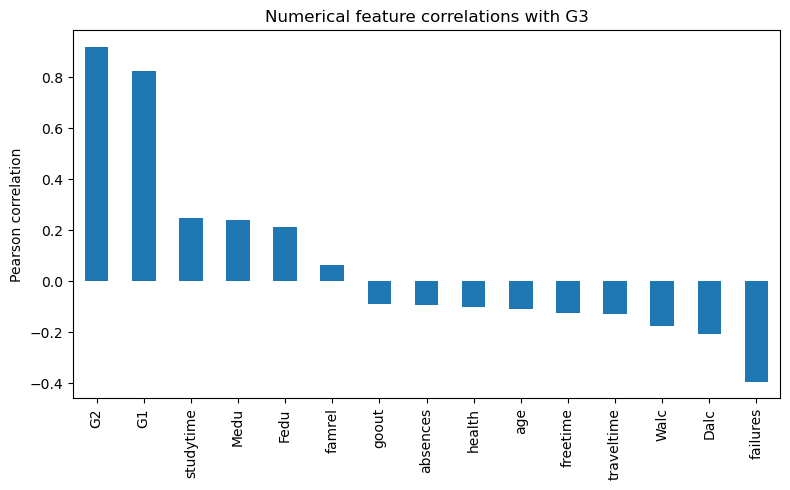

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
corr = df[numeric_columns].corr(numeric_only=True)
grade_corr = corr["G3"].drop("G3").sort_values(ascending=False)

print("Numerical feature correlations with final grade (EDA only):")
display(grade_corr.to_frame("Pearson correlation"))

fig, ax = plt.subplots(figsize=(8, 5))
grade_corr.plot(kind="bar", ax=ax)
ax.set(title="Numerical feature correlations with G3", ylabel="Pearson correlation")
plt.tight_layout()
plt.show()

## 5. Define features and split the dataset

**Why split before feature selection?** Choosing features using the test set would leak information into model development.

We use:
- **64% training** for feature selection and model fitting
- **16% validation** for tuning/model selection
- **20% test** for the final evaluation only

The splits are **stratified**, so category proportions remain approximately similar.

**Important:** This notebook performs EDA on the whole dataset for descriptive understanding, but all data-driven feature selection below uses **training rows only**.

In [6]:
TARGET = "performance_category"
X = df.drop(columns=["G3", TARGET])
y = df[TARGET]

assert "G1" in X.columns and "G2" in X.columns
assert "G3" not in X.columns
print("Candidate raw input features:", X.shape[1])

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")
print("Training class distribution:")
display(y_train.value_counts())

Candidate raw input features: 32
Train: 415 | Validation: 104 | Test: 130
Training class distribution:


performance_category
Average    227
Good       124
Low         64
Name: count, dtype: int64

## 6. Feature selection with Mutual Information

**Why this method?** Mutual Information (MI) estimates how much information an input feature provides about the performance category. It can capture some non-linear associations.

To keep this understandable:
- Encode categorical variables using an **OrdinalEncoder fitted only on training data** for MI ranking.
- Mark categorical features as discrete when computing MI.
- Keep `G1` and `G2` because the project specifically targets mid-course prediction.
- Select the **top 10 additional features**, giving **12 features total**.

**Important limitations:** MI scores are univariate, can vary on small datasets, and do not establish causation. The choice of 12 features is a practical starting point, **not a proven optimal number**. We will validate predictive performance in later notebooks. The actual DNN preprocessing will be fitted separately in Notebook 02.

,mutual_information
G2,0.623736
G1,0.453464
failures,0.063246
higher,0.059859
absences,0.050414
studytime,0.048674
school,0.042020
Fedu,0.041829
Medu,0.034248
Mjob,0.024029


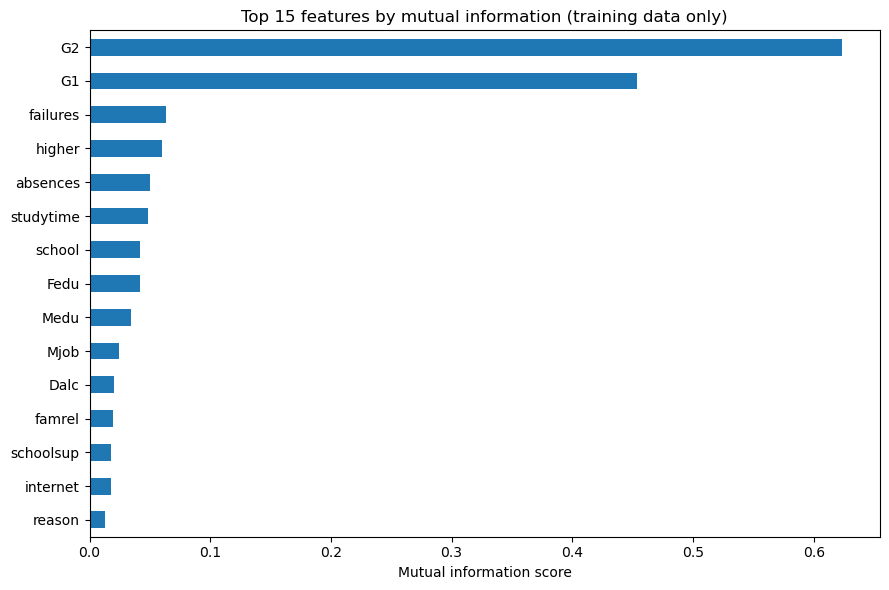

In [7]:
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

mi_X = X_train.copy()
ordinal_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
mi_X[categorical_cols] = ordinal_encoder.fit_transform(X_train[categorical_cols])

# UCI student-por.csv normally has no missing values; fail clearly if this changes.
if mi_X.isna().any().any():
    raise ValueError("Missing values detected. Add train-only imputation before MI ranking.")

discrete_mask = [col in categorical_cols for col in mi_X.columns]

mi_values = mutual_info_classif(
    mi_X, y_train, discrete_features=discrete_mask, random_state=SEED
)
ranking = pd.Series(mi_values, index=mi_X.columns, name="mutual_information")
ranking = ranking.sort_values(ascending=False)

display(ranking.to_frame().head(20))

fig, ax = plt.subplots(figsize=(9, 6))
ranking.head(15).sort_values().plot(kind="barh", ax=ax)
ax.set(title="Top 15 features by mutual information (training data only)",
       xlabel="Mutual information score")
plt.tight_layout()
plt.show()

## 7. Select and save our compact feature list

We choose 12 raw inputs for the first model: `G1`, `G2` plus the 10 highest-ranked other features.

We save the list in a JSON file so every later notebook uses **exactly the same input columns**. This file is a **feature-selection configuration**, not a trained preprocessing model.

**Fairness and privacy note:** Some original features concern family circumstances, health or personal relationships. Review the selected list before deploying a real student-facing tool. This educational prototype is not appropriate for consequential decisions.

In [8]:
REQUIRED_FEATURES = ["G1", "G2"]
TOTAL_FEATURES = 12

other_features = [col for col in ranking.index if col not in REQUIRED_FEATURES]
selected_features = REQUIRED_FEATURES + other_features[:TOTAL_FEATURES - len(REQUIRED_FEATURES)]

assert len(selected_features) == TOTAL_FEATURES
assert set(selected_features).issubset(X_train.columns)

print("Selected features:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i:2d}. {feature} (MI = {ranking[feature]:.4f})")

CONFIG_PATH.parent.mkdir(parents=True, exist_ok=True)
config = {
    "prediction_stage": "mid_course_after_G2",
    "dataset": "student-por.csv",
    "target": TARGET,
    "target_source": "G3",
    "seed": SEED,
    "feature_selection": "training_only_mutual_information",
    "total_features": TOTAL_FEATURES,
    "selected_features": selected_features,
    "split": {"test_size": 0.20, "validation_fraction_of_development": 0.20}
}
CONFIG_PATH.write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"\nSaved: {CONFIG_PATH}")

Selected features:
 1. G1 (MI = 0.4535)
 2. G2 (MI = 0.6237)
 3. failures (MI = 0.0632)
 4. higher (MI = 0.0599)
 5. absences (MI = 0.0504)
 6. studytime (MI = 0.0487)
 7. school (MI = 0.0420)
 8. Fedu (MI = 0.0418)
 9. Medu (MI = 0.0342)
10. Mjob (MI = 0.0240)
11. Dalc (MI = 0.0199)
12. famrel (MI = 0.0193)

Saved: ..\models\selected_features.json


## 8. Final checks and what comes next

Notebook 02 will:
1. Read `models/selected_features.json`.
2. Recreate the **same** train/validation/test splits using seed 42.
3. Fit `StandardScaler` and `OneHotEncoder` **on training data only**.
4. Design and train the DNN using the selected features.
5. Evaluate on validation data (not the test set).

### Viva-ready explanation

> First, I explored the dataset and created three performance categories from the final grade G3. Since my system predicts after the second grading period, G1 and G2 are valid input features. I split the data before feature selection to avoid data leakage. I ranked candidate features using Mutual Information on training data, retained G1 and G2, and selected a compact set of 12 inputs. The selected feature list is saved so all models can use a consistent set of inputs.

**Remember:** Feature selection does not prove that the DNN will perform well. We must measure that in the next notebooks.


In [9]:
saved_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
assert saved_config["selected_features"] == selected_features
assert "G3" not in saved_config["selected_features"]
assert {"G1", "G2"}.issubset(saved_config["selected_features"])
print("PASS — Feature configuration saved and validated.")
print("Next: Notebook 02 — DNN architecture and training.")

PASS — Feature configuration saved and validated.
Next: Notebook 02 — DNN architecture and training.
